# 2. One set of original bias weights; any new observable

Default: an **analytical synthetic biased ensemble**, not BiVO4 simulation data.
It tests the complete COLVAR -> weights -> normal FES interface. To use your run,
set `COLVAR_PATH`, `CV_NAMES`, and optional `PT_CACHE` in the configuration cell.

A bias belongs to a saved configuration. Computing a new CV changes where that
configuration goes in the histogram, not its original bias weight. We use
log w = V_removed/(kBT) for an equilibrated quasi-static OPES segment; OPES `rct`
is not subtracted. Choose the ensemble you want by specifying which wall biases
to remove. Never add the same wall twice.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from bivo4_fes import *

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
OUT = ROOT / "results"
OUT.mkdir(exist_ok=True)

/opt/pyvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
COLVAR_PATH = None     # e.g. Path("/your/run0/COLVAR")
PT_CACHE = None        # e.g. Path("/your/run0/pt.npz"); must match this COLVAR
CV_NAMES = ["d1", "cn"]
BIAS_COLUMNS = ["total_bias"]  # or ["opes.bias"] with deliberately retained walls
RECONSTRUCT_ORIGINAL_WALLS = False  # exact original input only; not with total_bias
TEMPERATURE = 350.0
DISCARD_BEFORE_PS = 0.0          # choose from bias/sampling convergence, not this demo

if COLVAR_PATH is None:
    print("SYNTHETIC DEMONSTRATION -- not a physical BiVO4 FES")
    rng = np.random.default_rng(31)
    kBT = 8.617333262145e-5 * TEMPERATURE
    # U = a*(x^2+y^2), V = -U/2, so sampled U+V = U/2.
    a = 0.04
    q = rng.normal(scale=np.sqrt(kBT/a), size=(4000, 2))
    bias_eV = -0.5*a*np.sum(q*q, axis=1)
    demo = {"time": np.arange(len(q))*0.1, "x": q[:,0], "y": q[:,1],
            "opes.bias": bias_eV*96.4853321233}
    COLVAR_PATH = OUT / "synthetic_COLVAR"
    write_colvar(COLVAR_PATH, demo)
    CV_NAMES, BIAS_COLUMNS = ["x", "y"], ["opes.bias"]
    BOUNDS, BINS, BANDWIDTH = [[-1.2, 1.2], [-1.2, 1.2]], [101, 101], [0.12, 0.12]
else:
    BOUNDS, BINS, BANDWIDTH = [[2.0, 4.5], [0.6, 2.6]], [201, 201], [0.04, 0.04]

c = read_colvar(COLVAR_PATH)
bias = sum(c[name] for name in BIAS_COLUMNS)
if RECONSTRUCT_ORIGINAL_WALLS:
    if "total_bias" in BIAS_COLUMNS:
        raise ValueError("Do not add walls twice.")
    bias = bias + original_walls(c)
lw_all = opes_logweights(bias, temperature=TEMPERATURE, unit="kJ/mol")
keep = c["time"] >= DISCARD_BEFORE_PS
print(weight_diagnostics(lw_all[keep]))

SYNTHETIC DEMONSTRATION -- not a physical BiVO4 FES
{'frames': 4000, 'kish_ess': 2964.292248271384, 'largest_weight_fraction': 0.000509311326389352}


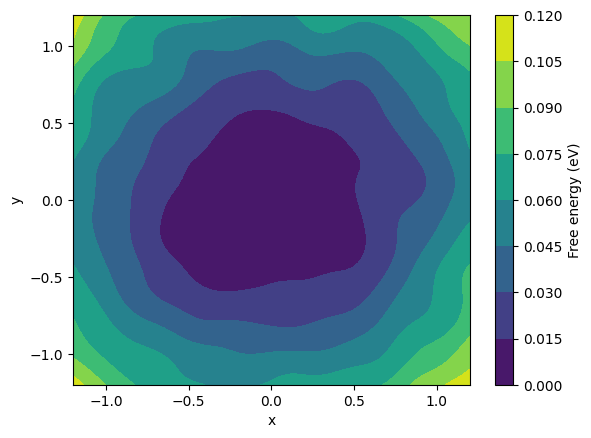

Normalization: selected
Kish ESS: 2964.292248271384 (not independent time samples)


In [3]:
samples = np.column_stack([c[name] for name in CV_NAMES])
fes = compute_fes(samples[keep], lw_all[keep], bounds=BOUNDS, bins=BINS,
                  bandwidth=BANDWIDTH, temperature=TEMPERATURE,
                  unit="eV", method="local")
ax = fes.plot(vmax=0.2)
ax.set(xlabel=CV_NAMES[0], ylabel=CV_NAMES[1])
plt.show()
fes.save(OUT / "ordinary_fes.npz")
fes.to_plumed(OUT / "ordinary_fes.dat", CV_NAMES)
print("Normalization:", fes.metadata["normalization"])
print("Kish ESS:", fes.metadata["kish_ess"], "(not independent time samples)")

## Faster approximation versus local Gaussian calculation

`local` evaluates each Gaussian at the actual grid coordinates within 12 sigma,
in log space. `binned` first assigns observations to grid bins and convolves:
faster, but not identical. Grid spacing must be no more than half the bandwidth.
`exact` is a slow full-tail reference for small validation cases.

Do not hide a disagreement by clipping the FES before computing a barrier.
The following comparison uses the current demonstration grid.

In [4]:
binned = compute_fes(samples[keep], lw_all[keep], bounds=BOUNDS, bins=BINS,
                     bandwidth=BANDWIDTH, temperature=TEMPERATURE, unit="eV",
                     method="binned")
relevant = np.isfinite(fes.free_energy) & (fes.free_energy < 0.15)
print("Max local/binned difference below 0.15 eV:",
      np.max(abs(fes.free_energy[relevant] - binned.free_energy[relevant])))

Max local/binned difference below 0.15 eV: 0.0007261733046158292


## Physical PT reweighting: explicit matching, then the SAME calculation

This block is skipped until a matching PT cache is supplied. The included sample
trajectory was not verified against the earlier COLVAR0, so it is intentionally
not used to generate a physical FES. The recalculated original CVs act as a second
identity check after timestamps match.

Below, each channel is conditional on having that geometric connection. Direct
and indirect can overlap; these are not automatically disjoint kinetic mechanisms.
The example bandwidth 0.03 A is not a claim that it is optimal for your data.

In [5]:
pt_fes = {}
if PT_CACHE is not None:
    pt = PTResult.load(PT_CACHE)
    rows = align_colvar(pt.time, c)
    print(check_cv_alignment(pt, c, rows))
    lw = lw_all[rows]
    retained = pt.time >= DISCARD_BEFORE_PS
    for channel in ("direct", "indirect"):
        q = pt.channel(channel)
        new_cvs = np.column_stack((q["delta"], q["distance"]))
        valid = retained & pt.valid(channel)
        print(channel, "valid frames:", valid.sum())
        if not valid.any():
            print("No observed connection: no FES is inferred for this channel.")
            continue
        print(weight_diagnostics(lw[valid]))
        pt_fes[channel] = compute_fes(
            new_cvs[retained], lw[retained],
            bounds=[[-1.5, 1.5], [2.3, 3.5]], bins=[301, 201],
            bandwidth=[0.03, 0.03], temperature=TEMPERATURE, unit="eV")
        pt_fes[channel].save(OUT / f"{channel}_fes.npz")
        ax = pt_fes[channel].plot(vmax=1.5)
        ax.set(xlabel="delta (A)", ylabel="dOO / averaged dOO (A)", title=channel)
        plt.show()
else:
    print("PT FES skipped: set PT_CACHE and the matching real COLVAR_PATH.")

PT FES skipped: set PT_CACHE and the matching real COLVAR_PATH.


## Populations and normalization

For the same aligned frames, the conditional product population is the weighted
sum of each site indicator divided by the weighted product population. A -1 label
remains unresolved, rather than being silently forced onto a surface site.

For a *joint* channel density instead of a conditional one, pass
`log_normalizer=logsumexp(lw[retained])` to `compute_fes`. Examine
`-kBT*surface.log_density` rather than separately minimum-shifted curves to retain
that relative normalization. Even then, a rate ratio needs additional kinetic
assumptions and adequate sampling. Block stability matters more than a smooth plot.

In [6]:
if PT_CACHE is not None:
    sites = protonated_site(pt.surface_cn, pt.acceptors)
    product = retained & (pt.donor_cn < 1.3)
    if product.any():
        print("Conditional site populations (Python atom IDs):", populations(sites, lw, mask=product))
        print("Contiguous-block populations:", block_populations(sites, lw, mask=product, nblocks=4))
        print("Product weight concentration:", weight_diagnostics(lw[product]))

    # Alternative: include ALL candidate paths, splitting each frame's weight.
    # Requires keep_paths=True when geometry was analyzed.
    # cv_all, logw_all_paths, row_ids = all_path_samples(pt, "direct", lw)
    # use = retained[row_ids]
    # compute_fes(cv_all[use], logw_all_paths[use], bounds=..., bandwidth=...)
    # This defines a different observable from one selected path per frame.

## Existing legacy CV arrays can also use the fast FES code

```python
legacy = np.load("DirectPTOsi-mlp0.npy")
new_cvs = legacy[:, [1, 2]]  # exactly the columns in the colleague's notebook
# Match the bias to the SAME frames using their actual times/steps.
# Then call compute_fes(new_cvs, matched_logweights, ...).
```

This route preserves the original ECToolkits classification exactly and changes
only the density-estimation implementation. For a different Hamiltonian,
`opes_logweights(..., delta_energy=U_target-U_sampled)` is available; the energy
difference must use the same units and the ACTUALLY sampled Hamiltonian, including
any residual MLP-to-DFT correction. Check overlap before using perturbative weights.